# Text Mining I: turning messages into numbers
## The campus help desk inbox
**Salem Othman · Student notebook**

Every method so far needed numbers: visits per week, dollars, metres. Most of the data people actually produce is **text**: emails, reviews, chat messages, tickets.

The campus help desk received 248 messages last month. Nobody has sorted them. Today you will turn each message into a row of numbers (**bag of words**), weight the words so the useful ones count more (**TF-IDF**), find messages that say the same thing (**similarity**), and let k-means find the kinds of problem students write about (**topics**). That last step is the clustering you already know, on a new kind of row.

### Today's five steps
| Part | Step | What you do | Exercise |
|---|---|---|---|
| 1 | Bag of words | Turn 3 short messages into a table of word counts | E1 |
| 2 | The inbox | Do the same for all 248 messages | E2 |
| 3 | TF-IDF | Give rare, useful words more weight | E3 |
| 4 | Similar messages | Find past messages most like a new one | E4 |
| 5 | Topics | Cluster the messages and name each cluster | E5 |

**For every exercise:** predict → write the code → check → explain.

**How to work**
- Run cells from top to bottom with **Shift + Enter**.
- In an exercise cell, **write the code yourself** under each numbered step. Keep the variable names exactly as written; the Check cell looks for them.
- `PASS` means that step is done. `FIX` tells you what to look at.
- If a Check cell says an exercise **is not finished yet**, that is not an error: write the code in the exercise cell above, run it, then run the Check cell again.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 140)
RANDOM_STATE = 42

def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)

def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print("Write your code in the exercise cell above, run that cell, then run this one again.")
        return False
    return True

print("Setup complete.")

Setup complete.


# Part 0 · The inbox
Each row is one message a student sent to the help desk last month.

| Column | Meaning |
|---|---|
| `message_id` | The ticket number. Useful for tracing a message, never a model input. |
| `message` | What the student wrote |

There is **no category column**. The help desk manager wants to know what kinds of problem students write about, and wants a quick way to find old messages like a new one.

In [2]:
rng = np.random.default_rng(7)

# Last month's messages to the campus help desk. Nobody has sorted them into categories yet.
# Each message is built from a few pieces, the way real students write: a greeting (maybe),
# what is wrong, where, since when, and a request.
greetings = ["", "", "", "Hi, ", "Hello, ", "Hey, "]
places = ["in my room", "in Baker Hall", "on the 3rd floor of Rodgers", "in the library",
          "in the Annex", "in Evans Way dorm", "in my suite", "near the study lounge"]
times = ["since this morning", "again today", "every night this week", "for two days",
         "since Monday", "all weekend", ""]
asks = ["Please fix it.", "Can someone help?", "Thanks.", "This keeps happening.",
        "Who should I contact?", "Please send someone.", ""]

problems = {
    "wifi": ["the wifi keeps disconnecting", "the wifi is really slow", "I can't connect to the wifi",
             "the internet connection drops", "the network signal is weak", "eduroam won't let me log in",
             "the wifi router is blinking red", "my laptop loses the wireless connection"],
    "printing": ["the printer is jammed", "the printer is out of paper", "my print job is stuck in the queue",
                 "the printer says low toner", "my print credits were charged but nothing printed",
                 "color printing does not work", "the printer prints blank pages", "the scanner on the printer is broken"],
    "heating": ["the heat is not working", "the radiator is cold", "my room is freezing",
                "the thermostat is stuck on high", "it is way too hot and the heating won't turn off",
                "the heater makes a loud banging noise", "the air conditioning is blowing warm air",
                "the window does not close and the room is cold"],
    "dining": ["the dining hall food was cold", "the dining hall ran out of vegetarian options at dinner",
               "the lunch line is extremely long", "my meal swipe was charged twice",
               "the salad bar was empty at lunch", "the pizza at dinner was undercooked",
               "the dining hall menu online is wrong", "the dining hall closed early before dinner"],
    "laundry": ["the washing machine won't start", "the dryer takes my money but does not dry",
                "the laundry card reader is broken", "the washer leaked water on the floor",
                "my clothes came out of the dryer still wet", "two laundry machines are out of order",
                "the laundry room door is locked", "the washer stopped in the middle of the cycle"],
}
# A second sentence that adds detail about the same problem.
details = {
    "wifi": ["The wifi is unusable for my online classes.", "I already restarted the router.",
             "Other students have the same wifi problem.", "I need the internet for my online exam."],
    "printing": ["I need to print my lab report.", "I tried another printer and it did the same thing.",
                 "The printer screen shows an error.", "My assignment is due and I have to print it."],
    "heating": ["It is freezing at night.", "I had to sleep in a jacket.",
                "The heating was fine last week.", "Can maintenance check the heating?"],
    "dining": ["The food was not ready on time.", "I paid with my meal plan.",
               "Many students skipped dinner.", "The dining staff said they could not help."],
    "laundry": ["I lost two dollars in the machine.", "My clothes are still stuck in the washer.",
                "The laundry machines need repair.", "I have no clean clothes for tomorrow."],
}
# Dining and laundry happen in shared places, so they get their own locations.
topic_places = {"dining": ["at the main dining hall", "at Beatty Hall", "at the cafe", "at the food court"],
                "laundry": ["in the Baker Hall laundry room", "in the basement laundry room",
                            "in the Rodgers laundry room", "on the 1st floor"]}

def write_message(topic):
    where = rng.choice(topic_places.get(topic, places))
    text = f"{rng.choice(greetings)}{rng.choice(problems[topic])} {where} {rng.choice(times)}. {rng.choice(details[topic])} {rng.choice(asks)}"
    text = " ".join(text.split()).replace(" .", ".")
    return text[0].upper() + text[1:]

rows = []
for topic, n in [("wifi", 62), ("printing", 48), ("heating", 55), ("dining", 40), ("laundry", 35)]:
    rows += [write_message(topic) for _ in range(n)]
# A few students report two problems in one message.
for a, b in [("wifi", "printing"), ("heating", "wifi"), ("printing", "wifi"), ("laundry", "heating"),
             ("dining", "wifi"), ("heating", "printing"), ("wifi", "laundry"), ("printing", "heating")]:
    rows.append(f"{write_message(a)} Also, {rng.choice(problems[b])}.")

inbox = pd.DataFrame({"message": rows}).sample(frac=1, random_state=3).reset_index(drop=True)
inbox.insert(0, "message_id", [f"M{i:03d}" for i in range(1, len(inbox) + 1)])

print("Messages:", len(inbox))
display(inbox.head(8))

Messages: 248


,message_id,message
0,M001,"Hi, the network signal is weak in Evans Way dorm. Other students have the same wifi problem. Thanks."
1,M002,My print job is stuck in the queue in Baker Hall since Monday. I need to print my lab report. Can someone help?
2,M003,"Hi, the air conditioning is blowing warm air in my suite. It is freezing at night. This keeps happening."
3,M004,The printer prints blank pages in the Annex every night this week. I need to print my lab report. Please fix it.
4,M005,"Hello, the printer says low toner in Baker Hall. The printer screen shows an error."
5,M006,I can't connect to the wifi in the library. I need the internet for my online exam. Who should I contact?
6,M007,"Hi, I can't connect to the wifi in Evans Way dorm. I already restarted the router. Can someone help?"
7,M008,The wifi keeps disconnecting near the study lounge since Monday. The wifi is unusable for my online classes. Thanks.


**Write:** read the 8 messages above. What kinds of problem do you see? Which words told you?

*Your answer:*
I see that the printers don't work properly, the wifi is slow or does not connect. And the air conditioning is faulty.

# Part 1 · Bag of words, by hand
k-means, KNN and trees all need **rows of numbers with the same columns**. A message is a string of different length. The simplest fix is the **bag of words**: forget the word order, and count how many times each word appears.

1. Make every letter lowercase and split the message into words.
2. Remove **stop words**: very common words like *the, is, in, my* that appear in almost every message.
3. The **vocabulary** is every word left, in alphabetical order. Each word becomes one column.
4. Each message becomes one row: how many times it uses each word.

Here are the 3 short messages from the slides.

In [3]:
tiny_messages = [
    "The wifi is slow in my room today",
    "The printer is broken again today",
    "Wifi is broken in the library today",
]
for name, text in zip(["T1", "T2", "T3"], tiny_messages):
    print(name, ":", text)

T1 : The wifi is slow in my room today
T2 : The printer is broken again today
T3 : Wifi is broken in the library today


### E1 · The bag of words for 3 messages
`CountVectorizer` does steps 1–4 for you. `fit_transform` learns the vocabulary and counts in one go. It returns a **sparse matrix** (it only stores the non-zero numbers); `.toarray()` turns it into an ordinary table you can look at.

**Predict:** how many columns will the table have? Which words will be removed?
it will have 3 columns

In [4]:
tiny_vectorizer = None
tiny_counts = None

# Write your code below. Your code must create the variables set to None above.

# 1. tiny_vectorizer: a CountVectorizer that removes English stop words.
#    Hint: CountVectorizer(stop_words="english")
tiny_vectorizer = CountVectorizer(stop_words="english")

# 2. Learn the vocabulary and count the words of tiny_messages.
#    Hint: matrix = tiny_vectorizer.fit_transform(tiny_messages)
matrix = tiny_vectorizer.fit_transform(tiny_messages)
# 3. tiny_counts: a DataFrame of the counts, one row per message (T1, T2, T3),
#    one column per word. Display it.
#    Hint: pd.DataFrame(matrix.toarray(), columns=tiny_vectorizer.get_feature_names_out(),
#                       index=["T1", "T2", "T3"])
tiny_counts = pd.DataFrame(matrix.toarray(), columns=tiny_vectorizer.get_feature_names_out(), index=["T1", "T2", "T3"])
display(tiny_counts)

,broken,library,printer,room,slow,today,wifi
T1,0,0,0,1,1,1,1
T2,1,0,1,0,0,1,0
T3,1,1,0,0,0,1,1


**Check E1**

In [5]:
if ready(tiny_vectorizer, "E1") and ready(tiny_counts, "E1"):
    reference = CountVectorizer(stop_words="english")
    expected = reference.fit_transform(tiny_messages).toarray()
    check("one row per message", tiny_counts.shape[0] == len(tiny_messages))
    check("the columns are the vocabulary, A to Z", list(tiny_counts.columns) == sorted(tiny_counts.columns))
    check("stop words were removed (no 'the', 'is', 'in')", not {"the", "is", "in"} & set(tiny_counts.columns))
    check("the counts match CountVectorizer", np.array_equal(tiny_counts.to_numpy(), expected))

PASS  one row per message
PASS  the columns are the vocabulary, A to Z
PASS  stop words were removed (no 'the', 'is', 'in')
PASS  the counts match CountVectorizer


**Write:** compare your table with the one on the slides. Which words did the stop-word list remove? Is anything lost by removing them?

*Your answer:*
The stop word list removed everything besides: broken, library, printer, room, slow, today, wifi. Nothing important should be lost when removing them. 

# Part 2 · The whole inbox as a table
Same steps, 248 messages. Two things change at this size:
- The vocabulary has **hundreds** of words, so the table has hundreds of columns.
- Each message uses only about a dozen of them, so almost every cell is **0**. That's why scikit-learn stores it as a sparse matrix.

### E2 · Count the words of every message
**Predict:** which words will be the most common in the whole inbox? Will they tell you what the problem is?
The most common words will be words used like "fix" and "wifi".

In [6]:
vectorizer = None
counts = None
word_totals = None

# Write your code below. Your code must create the variables set to None above.

# 1. vectorizer: CountVectorizer(stop_words="english").
#    counts: the count matrix of inbox["message"].
#    Hint: vectorizer.fit_transform(inbox["message"])
vectorizer = CountVectorizer(stop_words="english")
counts = vectorizer.fit_transform(inbox["message"])
# 2. Print the shape of counts (messages, words) and the share of cells that are 0.
#    Hint: counts.shape;   1 - counts.nnz / (counts.shape[0] * counts.shape[1])
#    (nnz = "number of non-zero" cells)
print(
    f"Shape of counts: {counts.shape}\nCells that are 0: {1 - counts.nnz / (counts.shape[0] * counts.shape[1])}"
)
# 3. word_totals: how many times each word appears in the whole inbox,
#    largest first. Display the top 15.
#    Hint: pd.Series(np.asarray(counts.sum(axis=0)).ravel(),
#                    index=vectorizer.get_feature_names_out()).sort_values(ascending=False)
word_totals = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out()).sort_values(ascending=False)

display(word_totals.head(15))

Shape of counts: (248, 180)
Cells that are 0: 0.9386200716845878


hall       79
room       64
wifi       64
printer    59
night      54
hi         48
help       46
laundry    44
dining     43
monday     43
keeps      42
week       42
send       42
weekend    39
fix        37
dtype: int64

**Check E2**

In [7]:
if ready(vectorizer, "E2") and ready(counts, "E2") and ready(word_totals, "E2"):
    check("one row per message", counts.shape[0] == len(inbox))
    check("one column per vocabulary word", counts.shape[1] == len(vectorizer.get_feature_names_out()))
    check("word_totals has one value per word", len(word_totals) == counts.shape[1])
    check("word_totals is sorted, largest first", word_totals.is_monotonic_decreasing)
    check("word_totals adds up to every counted word", word_totals.sum() == counts.sum())

PASS  one row per message
PASS  one column per vocabulary word
PASS  word_totals has one value per word
PASS  word_totals is sorted, largest first
PASS  word_totals adds up to every counted word


### Worked example · The top 15 words

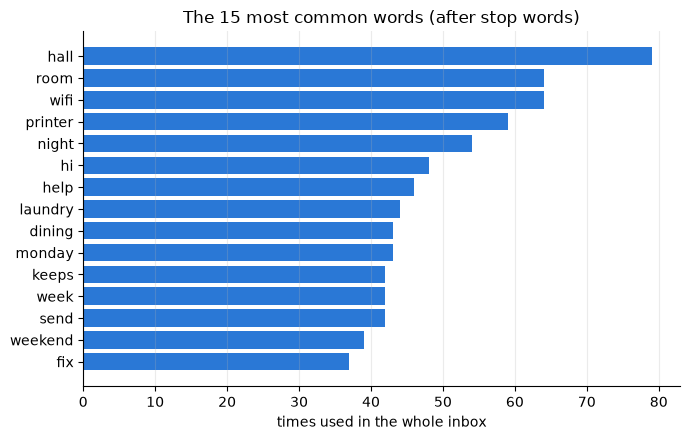

In [8]:
if ready(word_totals, "E2"):
    top = word_totals.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh(top.index, top.values, color="#2a78d6")
    ax.set_xlabel("times used in the whole inbox")
    ax.set_title("The 15 most common words (after stop words)")
    ax.grid(axis="x", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Write:** sort the top 15 words into two groups: words that tell you the problem, and words that don't. Why is a raw count a poor way to find the important words?

*Your answer:*
Raw count can be misleading, it may be a simple word like "fix" or "weekend" that does not relate to the issue at hand 

# Part 3 · TF-IDF: rare words count more
**TF-IDF** = **T**erm **F**requency × **I**nverse **D**ocument **F**requency. In plain words: *how often the word is in this message* × *how rare the word is across all messages*.

1. Count how many messages contain each word.
2. Give each word a weight: the fewer messages contain it, the bigger the weight. scikit-learn uses
   `weight = ln((1 + number of messages) / (1 + messages containing the word)) + 1`.
   With our 3 short messages: a word in 1 message gets **1.69**, in 2 messages **1.29**, in all 3 **1.00**.
3. Multiply: count × weight.
4. Scale each row so its length is 1, so long messages don't win just by being long.

The worked cell below repeats the slides' numbers, so you can see the code agrees with the hand calculation.

In [9]:
# Steps 1-3 only (norm=None turns off step 4), on the 3 short messages from the slides.
by_hand = TfidfVectorizer(stop_words="english", norm=None)
weighted = by_hand.fit_transform(tiny_messages)
print("weight of each word (step 2):")
display(pd.Series(by_hand.idf_, index=by_hand.get_feature_names_out()).round(2))
print("count x weight (step 3):")
display(pd.DataFrame(weighted.toarray(), columns=by_hand.get_feature_names_out(), index=["T1", "T2", "T3"]).round(2))

# All four steps: the default TfidfVectorizer.
full = TfidfVectorizer(stop_words="english")
print("after scaling each row to length 1 (step 4):")
display(pd.DataFrame(full.fit_transform(tiny_messages).toarray(), columns=full.get_feature_names_out(),
                     index=["T1", "T2", "T3"]).round(3))

weight of each word (step 2):


broken     1.29
library    1.69
printer    1.69
room       1.69
slow       1.69
today      1.00
wifi       1.29
dtype: float64

count x weight (step 3):


,broken,library,printer,room,slow,today,wifi
T1,0.00,0.00,0.00,1.69,1.69,1.0,1.29
T2,1.29,0.00,1.69,0.00,0.00,1.0,0.00
T3,1.29,1.69,0.00,0.00,0.00,1.0,1.29


after scaling each row to length 1 (step 4):


,broken,library,printer,room,slow,today,wifi
T1,0.000,0.000,0.00,0.584,0.584,0.345,0.445
T2,0.548,0.000,0.72,0.000,0.000,0.425,0.000
T3,0.480,0.632,0.00,0.000,0.000,0.373,0.480


### E3 · TF-IDF for the whole inbox
**Predict:** which words will get the **lowest** weight? Will they be the same words as your "don't tell the problem" list?

In [10]:
tfidf_vectorizer = None
tfidf = None
idf_table = None
top_words_first = None

# Write your code below. Your code must create the variables set to None above.

# 1. tfidf_vectorizer: TfidfVectorizer(stop_words="english").
#    tfidf: the TF-IDF matrix of inbox["message"].
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vectorizer.fit_transform(inbox["message"])
# 2. idf_table: the weight of each word, smallest first.
#    Display the 8 lowest and the 8 highest.
#    Hint: pd.Series(tfidf_vectorizer.idf_, index=tfidf_vectorizer.get_feature_names_out()).sort_values()
idf_table = pd.Series(
    tfidf_vectorizer.idf_, index=tfidf_vectorizer.get_feature_names_out()
).sort_values()

print(f"Lowest 8: {idf_table[:8]}\nHighest 8: {idf_table[-8:]}")

# 3. top_words_first: the 5 words with the highest TF-IDF value in the FIRST message,
#    largest first. Print the first message too, so you can compare.
#    Hint: pd.Series(tfidf[0].toarray().ravel(), index=tfidf_vectorizer.get_feature_names_out())
#          then .sort_values(ascending=False).head(5)

top_words_first = (
    pd.Series(
        tfidf[0].toarray().ravel(), index=tfidf_vectorizer.get_feature_names_out()
    )
    .sort_values(ascending=False)
    .head(5)
)

print(inbox["message"].iloc[0])

Lowest 8: hall       2.327798
room       2.423108
wifi       2.547161
night      2.605430
hi         2.625633
help       2.667305
printer    2.710790
monday     2.733263
dtype: float64
Highest 8: connect    5.131159
printed    5.131159
start      5.131159
salad      5.418841
card       5.418841
reader     5.418841
bar        5.418841
order      5.824306
dtype: float64
Hi, the network signal is weak in Evans Way dorm. Other students have the same wifi problem. Thanks.


**Check E3**

In [11]:
if ready(tfidf, "E3") and ready(idf_table, "E3") and ready(top_words_first, "E3"):
    row_lengths = np.sqrt(np.asarray(tfidf.multiply(tfidf).sum(axis=1)).ravel())
    check("one row per message", tfidf.shape[0] == len(inbox))
    check("every row has length 1 (step 4 was done)", np.allclose(row_lengths, 1))
    check("idf_table has one weight per word, smallest first",
          len(idf_table) == tfidf.shape[1] and idf_table.is_monotonic_increasing)
    check("top_words_first has 5 words, largest first",
          len(top_words_first) == 5 and top_words_first.is_monotonic_decreasing)
    check("top_words_first comes from the first message",
          np.isclose(top_words_first.iloc[0], tfidf[0].toarray().max()))

PASS  one row per message
PASS  every row has length 1 (step 4 was done)
PASS  idf_table has one weight per word, smallest first
PASS  top_words_first has 5 words, largest first
PASS  top_words_first comes from the first message


**Write:** (a) Which words got the lowest weights? Are they your "don't tell the problem" words? Any surprises? (b) In the first message, which words got the biggest TF-IDF value, and why those?

*Your answer:*
room, wifi, night, hi, help, printer, and monday got the lowest weights. most of them tell the problem. 

# Part 4 · Find similar messages
Now every message is a row of TF-IDF numbers, so we can measure how alike two messages are. For text the usual measure is **cosine similarity**:

1. Line up the two rows.
2. Multiply the weights of the words they **share** (a word in only one message adds 0).
3. Add them up.

Because every row has length 1, the result is between **0** (no words in common) and **1** (the same words in the same proportions).

**One rule from the scaler applies here too.** The vectorizer learned its vocabulary and weights from the inbox. A new message must be turned into numbers with the **same** vocabulary, so use `.transform`, not `.fit_transform`.

### E4 · Which past messages are like this new one?
A student just wrote: **"The wifi in my dorm room is down again"**.

**Predict:** which word in it will matter most for finding matches? Which words will be ignored?

In [12]:
new_vector = None
similarity = None
best_matches = None

new_message = "The wifi in my dorm room is down again"

# Write your code below. Your code must create the variables set to None above.

# 1. new_vector: new_message as TF-IDF numbers, using the vectorizer from E3.
#    Hint: tfidf_vectorizer.transform([new_message])   (a list with one message; NOT fit_transform)
new_vector = tfidf_vectorizer.transform([new_message])

# 2. similarity: the cosine similarity between new_vector and every inbox message, as a flat array.
#    Hint: cosine_similarity(new_vector, tfidf).ravel()
similarity = cosine_similarity(new_vector, tfidf).ravel()

# 3. best_matches: the 3 inbox messages with the highest similarity, with a similarity column.
#    Hint: inbox.assign(similarity=similarity).sort_values("similarity", ascending=False).head(3)
best_matches = inbox.assign(similarity=similarity).sort_values("similarity", ascending=False).head(3)
display(best_matches)

,message_id,message,similarity
93,M094,"Hi, the wifi keeps disconnecting in Evans Way dorm since this morning. Other students have the same wifi problem. Thanks.",0.425351
116,M117,The wifi router is blinking red in Evans Way dorm all weekend. Other students have the same wifi problem. Who should I contact?,0.417830
58,M059,The wifi keeps disconnecting in Evans Way dorm for two days. I already restarted the router.,0.360305


**Check E4**

In [13]:
if ready(new_vector, "E4") and ready(similarity, "E4") and ready(best_matches, "E4"):
    check("new_vector uses the inbox vocabulary (same number of columns)", new_vector.shape == (1, tfidf.shape[1]))
    check("one similarity per inbox message", len(similarity) == len(inbox))
    check("every similarity is between 0 and 1", bool(np.all((similarity >= -1e-9) & (similarity <= 1 + 1e-9))))
    check("best_matches has the 3 most similar messages, best first",
          len(best_matches) == 3 and best_matches["similarity"].is_monotonic_decreasing
          and np.isclose(best_matches["similarity"].iloc[0], similarity.max()))

PASS  new_vector uses the inbox vocabulary (same number of columns)
PASS  one similarity per inbox message
PASS  every similarity is between 0 and 1
PASS  best_matches has the 3 most similar messages, best first


**Write:** (a) Are the 3 matches about the same problem? Which words did they share with the new message? (b) Why must it be `.transform` and not `.fit_transform`? (c) Change `new_message` to a problem of your own and run E4 again. Did it work?

*Your answer:*
The 3 messages are about the same issue in the same place, the wifi is not working in the evans way dorm. It must be .transform so we match against the original vocabulary. 

# Part 5 · Topics: k-means on text
Every message is now a row of numbers, so the k-means you used on café customers works unchanged. Two things are new:

- **Reading a cluster.** Each cluster centre is the average TF-IDF row of its messages. The words with the **biggest centre weights** describe the cluster: they are its topic.
- **Silhouette is low for text.** With hundreds of columns that are mostly 0, all messages look fairly far apart, so silhouette scores of 0.1 to 0.2 are normal even when the topics are clear. Judge the clusters by reading their top words and a few messages.

The help desk manager thinks there are about five kinds of problem, so start with k = 5.

### E5 · Find the topics
**Predict:** will each cluster's top words make sense as one kind of problem?

In [14]:
topic_model = None
topic_sizes = None
top_terms = None
text_silhouette = None

k_topics = 5

# Write your code below. Your code must create the variables set to None above.

# 1. topic_model: KMeans(n_clusters=k_topics, n_init=10, random_state=RANDOM_STATE) fitted on tfidf.
topic_model = KMeans(n_clusters=k_topics, n_init=10, random_state=RANDOM_STATE).fit(tfidf)

# 2. topic_sizes: how many messages are in each cluster.
#    Hint: pd.Series(topic_model.labels_).value_counts().sort_index()
topic_sizes = pd.Series(topic_model.labels_).value_counts().sort_index()

# 3. top_terms: a dictionary {cluster number: list of its 8 top words}. Print it.
#    Hint: terms = tfidf_vectorizer.get_feature_names_out()
#    Hint: for cluster j: list(terms[np.argsort(topic_model.cluster_centers_[j])[::-1][:8]])
#          (argsort sorts small to big; [::-1] flips it; [:8] keeps 8)
top_terms = {
    j: list(
        tfidf_vectorizer.get_feature_names_out()[
            np.argsort(topic_model.cluster_centers_[j])[::-1][:8]
        ]
    )
    for j in range(k_topics)
}
display(top_terms)

# 4. text_silhouette: silhouette_score(tfidf, topic_model.labels_, metric="cosine"). Print it.
text_silhouette = silhouette_score(tfidf, topic_model.labels_, metric="cosine")
print(text_silhouette)

{0: ['laundry',
  'clothes',
  'washer',
  'room',
  'floor',
  'clean',
  'tomorrow',
  'dryer'],
 1: ['dining', 'hall', 'food', 'dinner', 'meal', 'beatty', 'time', 'ready'],
 2: ['printer', 'print', 'did', 'thing', 'tried', 'report', 'lab', 'error'],
 3: ['freezing',
  'heating',
  'air',
  'night',
  'jacket',
  'sleep',
  'room',
  'maintenance'],
 4: ['wifi',
  'router',
  'internet',
  'online',
  'connection',
  'problem',
  'restarted',
  'students']}

0.19218434118667493


**Check E5**

In [15]:
if ready(topic_model, "E5") and ready(topic_sizes, "E5") and ready(top_terms, "E5") and ready(text_silhouette, "E5"):
    check("topic_model found k_topics clusters", topic_model.n_clusters == k_topics)
    check("every message is in a cluster", topic_sizes.sum() == len(inbox))
    check("top_terms has one list per cluster", len(top_terms) == k_topics)
    check("each list has 8 words from the vocabulary",
          all(len(words) == 8 and set(words) <= set(tfidf_vectorizer.get_feature_names_out())
              for words in top_terms.values()))
    check("text_silhouette is between -1 and 1", -1 <= text_silhouette <= 1)

PASS  topic_model found k_topics clusters
PASS  every message is in a cluster
PASS  top_terms has one list per cluster
PASS  each list has 8 words from the vocabulary
PASS  text_silhouette is between -1 and 1


### Worked example · Read two messages from each cluster

In [16]:
if ready(topic_model, "E5"):
    clustered = inbox.assign(cluster=topic_model.labels_)
    for j in range(k_topics):
        print(f"Cluster {j} ({(clustered['cluster'] == j).sum()} messages): {', '.join(top_terms[j][:5])}")
        for text in clustered.loc[clustered["cluster"] == j, "message"].head(2):
            print("   -", text)

Cluster 0 (36 messages): laundry, clothes, washer, room, floor
   - Hey, my clothes came out of the dryer still wet in the Baker Hall laundry room since Monday. The laundry machines need repair. Who should I contact?
   - Hello, the washer stopped in the middle of the cycle in the basement laundry room. The laundry machines need repair. Can someone help?
Cluster 1 (41 messages): dining, hall, food, dinner, meal
   - Hi, the dining hall ran out of vegetarian options at dinner at the food court again today. The food was not ready on time.
   - My meal swipe was charged twice at the cafe since this morning. Many students skipped dinner. Can someone help?
Cluster 2 (50 messages): printer, print, did, thing, tried
   - My print job is stuck in the queue in Baker Hall since Monday. I need to print my lab report. Can someone help?
   - The printer prints blank pages in the Annex every night this week. I need to print my lab report. Please fix it.
Cluster 3 (56 messages): freezing, heating, ai

**Write:** give each cluster a short name, and say which top words justify it. Silhouette is far below 0.5. Are the topics real?

*Your answer:*
The five clusters are:
0. Laundry (laundry, washer)
1. Dining (dining, food)
2. Printing (print, printer)
3. HVAC (freezing, heating)
4. WIFI (wifi, router)

The topics are real. 

### The AI's analysis
The help desk manager asks an AI assistant to analyse the inbox. It replies:

> "I clustered your 248 messages into 5 groups. Unfortunately the silhouette score is only 0.19, far below the 0.5 that shows real structure, so these messages have no clear topics and the clusters should not be used. If you do use them, fix wifi first: it is the biggest cluster, so it is the most urgent problem. For cleaning I removed English stop words, which only deletes meaningless words like *the* and *is*, so no information is lost."

Each claim can be checked. You may write code in the cell below to test the last one.

In [17]:
# Optional: test the AI's claim about stop words here.

**Write:** find **three** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. In higher dimensions a sihlouette score of 0.1-0.2 is expected. 
2. Cluster size measures frequency/volume and does not account for urgency or severity. 
3. Some english words like "not" can invert the meaning and removes critical context. 

### Challenge tasks (optional)
1. Run E5 with `k_topics = 4` and `k_topics = 7`. Which topics merge at 4? What do the extra clusters at 7 look like?
2. Make a vectorizer that keeps *not* and *down*: `CountVectorizer(stop_words=[w for w in CountVectorizer(stop_words="english").get_stop_words() if w not in {"not", "down"}])`. Does E4 find better matches?
3. Use `TfidfVectorizer(stop_words="english", ngram_range=(1, 2))` so two-word phrases like *not working* become columns. How many columns do you get now?

# Exit ticket
Answer without running more code.
1. In the count matrix, what is one row, what is one column, and why are most cells 0?
2. A word appears in almost every message. What does TF-IDF do to its weight, and why is that useful?
3. Why do we use `.transform`, not `.fit_transform`, on a new message?

*Your answers:*
1. Row: one document, Column: unique word. A single message uses a tiny fraction of the vocabulary. 
2. TF-IDF lowers it's weight, common words provide little information to a specific topic. 
3. We use transform to use existing vocabulary and weights from the training data. 

# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* and *Your prediction* cell is filled in.
- Submit this notebook with its outputs.